# Graph-local signal: saved FinGraph output and deciles

This notebook displays the saved graph-local mean-reversion backtest.  The graph is estimated separately; the strategy applies the active graph to the top-500 prior-day-market-cap universe, forms a signal at the close of `t`, and earns market-excess return at `t+1`.  Saved weights are 1% winsorized, z-scored, de-meaned, gross one, and net zero.

It also sorts the continuous graph-local `raw_signal` into daily D1–D10 portfolios.  D1 is the highest score, D10 the lowest.  The endpoint book is `+0.5 × D1 − 0.5 × D10`, hence gross one and net zero.

To rerun the signal backtest from the saved graph exports, use `local/README_graph_local.md`.


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline


def project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root")


ROOT = project_root()
sys.path.insert(0, str(ROOT / "local"))
from decile_analysis import cumulative_log_returns, decile_portfolios

BACKTEST = ROOT / "data/derived/fingraph_current_pnl/backtest"
SAMPLE_DATE = "2010-01-04"


In [3]:
daily = pd.read_csv(BACKTEST / "graph_local_daily.csv", parse_dates=["date"]).set_index("date")
metrics = pd.read_csv(BACKTEST / "performance_metrics.csv", index_col="method")
weights = pd.read_csv(
    BACKTEST / "daily_weights.csv.gz",
    compression="gzip",
    parse_dates=["date", "payoff_date", "refit_date"],
    dtype={"permno": str},
)
weights = weights.loc[weights.method.eq("graph_local")].copy()

display(metrics.loc[["graph_local"]])
sample = weights.loc[weights.date.eq(pd.Timestamp(SAMPLE_DATE)), ["permno", "raw_signal", "weight"]]
display(pd.concat([
    sample.sort_values("weight", ascending=False).head(6),
    sample.sort_values("weight", ascending=True).head(6),
]).reset_index(drop=True))

exposure = weights.groupby("date").weight.agg(net="sum", gross=lambda x: x.abs().sum())
assert np.allclose(exposure.net, 0.0, atol=1e-12)
assert np.allclose(exposure.gross, 1.0, atol=1e-12)


,days,start,end,AnnRet,AnnVol,Sharpe,AvgDlyBets,2WayTurnover,MDD,t_stat,cumulative_simple_return
method,,,,,,,,,,,
graph_local,3718,2010-01-04,2024-10-10,0.046537,0.032197,1.445377,476.9844,0.642529,-0.115206,5.551822,0.686606


,permno,raw_signal,weight
0,TECK.91321,0.070865,0.006601
1,EXPE.90808,0.036850,0.006601
2,PFG.89195,0.037517,0.006601
3,M.77462,0.047600,0.006601
4,BPO.86938,0.056153,0.006601
5,RCL.79145,0.036224,0.006584
6,DVN.87137,-0.042452,-0.007242
7,SHLD.89757,-0.044887,-0.007242
8,HRB.49373,-0.086206,-0.007242
9,MU.53613,-0.042788,-0.007242


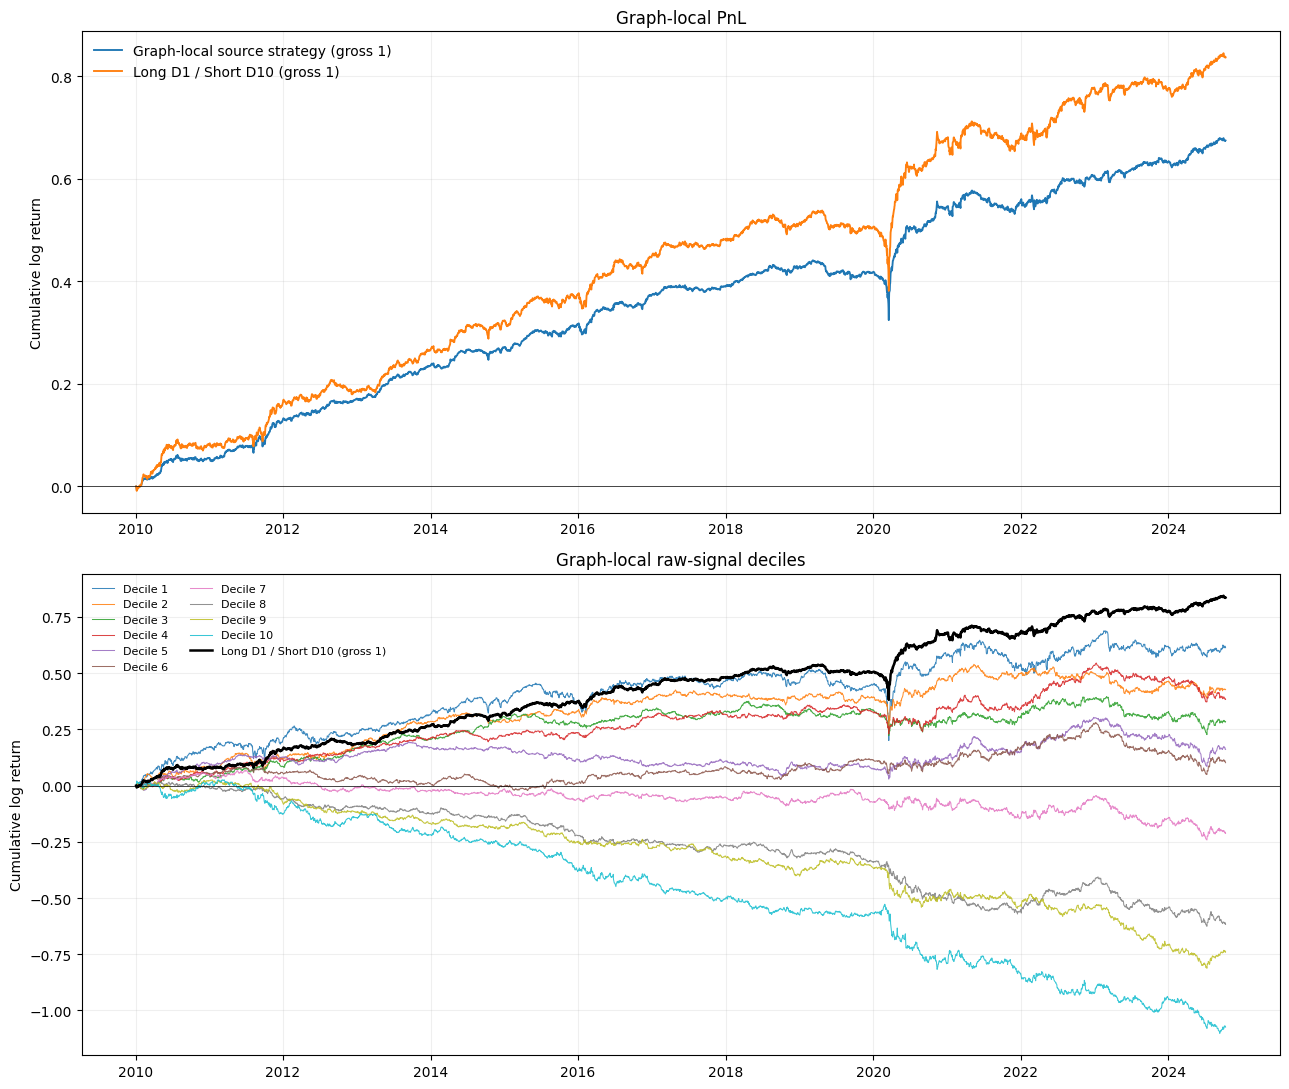

In [4]:
books = pd.read_csv(
    BACKTEST / "graph_local_daily_books.csv.gz",
    compression="gzip",
    parse_dates=["signal_date", "payoff_date"],
    dtype={"permno": str},
)
# `payoff_return` has already been paired with the t-close signal, so no lag is
# applied here. Decile 1 is the highest graph-local raw signal.
deciles = decile_portfolios(
    books,
    date_col="signal_date",
    asset_col="permno",
    return_col="payoff_return",
    score_col="raw_signal",
    higher_is_decile_1=True,
)

original = daily.daily_excess_return
endpoint = deciles.daily_returns["long_decile_1_short_decile_10"]
original_curve = cumulative_log_returns(original)
original_curve = original_curve - original_curve.iloc[0]
endpoint_curve = cumulative_log_returns(endpoint)
endpoint_curve = endpoint_curve - endpoint_curve.iloc[0]
decile_curve = deciles.cumulative_log_returns - deciles.cumulative_log_returns.iloc[0]

fig, axes = plt.subplots(2, 1, figsize=(13, 11))
axes[0].plot(original_curve.index, original_curve, lw=1.35, label="Graph-local source strategy (gross 1)")
axes[0].plot(endpoint_curve.index, endpoint_curve, lw=1.35, label="Long D1 / Short D10 (gross 1)")
axes[0].axhline(0, color="black", lw=.5)
axes[0].set(title="Graph-local PnL", xlabel="", ylabel="Cumulative log return")
axes[0].grid(alpha=.2)
axes[0].legend(frameon=False)

for column in [f"decile_{i}" for i in range(1, 11)]:
    axes[1].plot(decile_curve.index, decile_curve[column], lw=.75, alpha=.85, label=column.replace("_", " ").title())
axes[1].plot(decile_curve.index, decile_curve["long_decile_1_short_decile_10"], color="black", lw=1.8, label="Long D1 / Short D10 (gross 1)")
axes[1].axhline(0, color="black", lw=.5)
axes[1].set(title="Graph-local raw-signal deciles", xlabel="", ylabel="Cumulative log return")
axes[1].grid(alpha=.2)
axes[1].legend(ncol=2, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()


In [5]:
def performance_row(name, daily_return):
    x = daily_return.dropna()
    ann_vol = x.std(ddof=1) * np.sqrt(252)
    return {
        "series": name,
        "days": len(x),
        "AnnRet": x.mean() * 252,
        "AnnVol": ann_vol,
        "Sharpe": (x.mean() * 252) / ann_vol,
        "CumLogReturn": np.log1p(x).sum(),
    }

comparison = pd.DataFrame([
    performance_row("Graph-local source strategy (gross 1)", original),
    performance_row("Long D1 / short D10 (gross 1)", endpoint),
]).set_index("series")
display(comparison.style.format({
    "AnnRet": "{:.2%}", "AnnVol": "{:.2%}", "Sharpe": "{:.3f}", "CumLogReturn": "{:.3f}",
}))
display(deciles.holdings.describe().T)


,days,AnnRet,AnnVol,Sharpe,CumLogReturn
series,,,,,
Graph-local source strategy (gross 1),3718,4.65%,3.22%,1.445,0.679
Long D1 / short D10 (gross 1),3718,5.83%,4.55%,1.280,0.844


,count,mean,std,min,25%,50%,75%,max
decile_1,3718.0,48.140667,0.723827,46.0,48.0,48.0,49.0,50.0
decile_2,3718.0,48.036848,0.728370,45.0,48.0,48.0,49.0,50.0
decile_3,3718.0,47.939484,0.724561,45.0,48.0,48.0,48.0,50.0
decile_4,3718.0,47.848575,0.727223,45.0,47.0,48.0,48.0,49.0
decile_5,3718.0,47.749059,0.733691,45.0,47.0,48.0,48.0,49.0
decile_6,3718.0,47.653308,0.728030,45.0,47.0,48.0,48.0,49.0
decile_7,3718.0,47.548682,0.727397,45.0,47.0,48.0,48.0,49.0
decile_8,3718.0,47.455890,0.739425,45.0,47.0,47.0,48.0,49.0
decile_9,3718.0,47.360409,0.734824,45.0,47.0,47.0,48.0,49.0
decile_10,3718.0,47.251479,0.729830,45.0,47.0,47.0,48.0,49.0
